# 03 — Capacity: what binds first, and at what load

Everything after this notebook depends on one number: **how many concurrent
sessions this cluster can hold while keeping its latency promise.** Pick it
before measuring and it is a wish; derive it here and 04 and 05 have a
defensible operating point to compare against.

The second question matters just as much. An admission policy reads *one*
signal — KV usage, or queue depth. If that signal never moves, the policy
never fires and an A/B against it measures nothing. So before testing any
policy we have to find out **which resource runs out first.**

Run `make cluster` and `make ssh` first. This notebook generates real load
and takes several minutes.


In [1]:
import subprocess, sys, time, json, threading
from pathlib import Path

ROOT = Path.cwd().parents[1] if Path.cwd().name == '03-capacity' else Path.cwd()
sys.path.insert(0, str(ROOT / 'benchmarking'))
%load_ext autoreload
%autoreload 2

from prom import Prom
from utils import Cluster, Report
from slos import SLOS, set_target_sessions

prom, cluster = Prom(), Cluster()
report = Report('03-capacity')
v = lambda q: (lambda r: float(r[0][1]) if r else 0.0)(prom.query(q))


## Objective


In [2]:
report.objective(
    'How many concurrent sessions hold the TTFT promise, and which resource '
    'runs out first — KV cache, decode slots, or scheduling?',
    slos=['ttft_p95', 'preemptions', 'shed_rate'],
    falsified_by='TTFT p95 crossing 1.5s at any load we intend to serve, or no '
                 'signal moving at all — which would mean we never reached '
                 'saturation and cannot claim a capacity limit.')



Objective
  How many concurrent sessions hold the TTFT promise, and which resource runs out first — KV cache, decode slots, or scheduling?
  SLO under test            target
  ------------------------  ------
  TTFT p95                  1.5s  
  preemptions               0     
  shed rate at target load  0.05  
  Falsified by: TTFT p95 crossing 1.5s at any load we intend to serve, or no signal moving at all — which would mean we never reached saturation and cannot claim a capacity limit.


Report(title='03-capacity', subtitle='', blocks=[_Block(kind='heading', payload='Objective', note=''), _Block(kind='text', payload='How many concurrent sessions hold the TTFT promise, and which resource runs out first — KV cache, decode slots, or scheduling?', note=''), _Block(kind='table', payload=(['SLO under test', 'target'], [['TTFT p95', '1.5s'], ['preemptions', '0'], ['shed rate at target load', '0.05']]), note=''), _Block(kind='text', payload='Falsified by: TTFT p95 crossing 1.5s at any load we intend to serve, or no signal moving at all — which would mean we never reached saturation and cannot claim a capacity limit.', note='')])

## 1. What the hardware allows

Two independent ceilings, and the lower one is the real limit:

- **KV cache** — each slice holds a fixed number of token-KVs.
- **Decode slots** — `--max-num-seqs` caps concurrent sequences regardless of
  how much KV is free.

Which binds depends entirely on prompt length, so compute it rather than
assume it.


In [3]:
KIB_PER_TOKEN = 56      # 28 layers x 4 kv-heads x 128 head-dim x 2 (k+v) x 2 bytes
SLICE_KV_GIB  = 4.10    # measured on a slice, not divided down from the card
MAX_NUM_SEQS  = 64      # from the manifests

# Measured, not assumed. Which ceiling binds depends entirely on prompt
# length, so guessing it would decide the answer before the measurement.
p_tok = v('sum(increase(vllm:prompt_tokens_total[1h]))')
p_req = v('sum(increase(vllm:request_success_total[1h]))')
PROMPT_TOKENS = p_tok / p_req if p_req else 0

kv_per_seq_gib = PROMPT_TOKENS * KIB_PER_TOKEN / 1024 / 1024
seqs_by_kv     = SLICE_KV_GIB / kv_per_seq_gib if kv_per_seq_gib else float('inf')
binding        = 'KV cache' if seqs_by_kv < MAX_NUM_SEQS else 'decode slots'

report.heading('1. What the hardware allows')
report.table(['ceiling', 'concurrent sequences', 'why'], [
    ['KV cache', f'{seqs_by_kv:.1f}',
     f'{SLICE_KV_GIB} GiB / {kv_per_seq_gib:.2f} GiB per prompt'],
    ['decode slots', f'{MAX_NUM_SEQS}', '--max-num-seqs, independent of KV'],
], note=f'measured prompt length: {PROMPT_TOKENS:,.0f} tokens. '
        'The lower number is the ceiling that actually applies.')
report.conclusion(
    f'Prompts here average {PROMPT_TOKENS:,.0f} tokens, so each sequence costs '
    f'{kv_per_seq_gib:.2f} GiB of KV and a {SLICE_KV_GIB} GiB slice holds '
    f'{seqs_by_kv:.1f} of them — against {MAX_NUM_SEQS} decode slots. '
    f'{binding} binds first, so that is the signal an admission policy should '
    'read. This is a property of the workload, not the hardware: at short '
    'prompts the same cluster would bind on slots instead and a KV-threshold '
    'policy would never fire.')



1. What the hardware allows
  ceiling       concurrent sequences  why                              
  ------------  --------------------  ---------------------------------
  KV cache                      35.9  4.1 GiB / 0.11 GiB per prompt    
  decode slots                    64  --max-num-seqs, independent of KV
  -- measured prompt length: 2,137 tokens. The lower number is the ceiling that actually applies.

  >> Prompts here average 2,137 tokens, so each sequence costs 0.11 GiB of KV and a 4.1 GiB slice holds 35.9 of them — against 64 decode slots. KV cache binds first, so that is the signal an admission policy should read. This is a property of the workload, not the hardware: at short prompts the same cluster would bind on slots instead and a KV-threshold policy would never fire.



Report(title='03-capacity', subtitle='', blocks=[_Block(kind='heading', payload='Objective', note=''), _Block(kind='text', payload='How many concurrent sessions hold the TTFT promise, and which resource runs out first — KV cache, decode slots, or scheduling?', note=''), _Block(kind='table', payload=(['SLO under test', 'target'], [['TTFT p95', '1.5s'], ['preemptions', '0'], ['shed rate at target load', '0.05']]), note=''), _Block(kind='text', payload='Falsified by: TTFT p95 crossing 1.5s at any load we intend to serve, or no signal moving at all — which would mean we never reached saturation and cannot claim a capacity limit.', note=''), _Block(kind='heading', payload='1. What the hardware allows', note=''), _Block(kind='table', payload=(['ceiling', 'concurrent sequences', 'why'], [['KV cache', '35.9', '4.1 GiB / 0.11 GiB per prompt'], ['decode slots', '64', '--max-num-seqs, independent of KV']]), note='measured prompt length: 2,137 tokens. The lower number is the ceiling that actually 

## 2. The sweep

Same workload, same seed, one variable: concurrent sessions. Each step runs
`load.py` and samples the scarcity signals while it runs — a latency number
without the pressure beside it cannot tell a healthy cluster from one that
was never asked for anything.


In [4]:
SESSIONS = [1, 2, 4, 8, 16, 24]
SEED     = 1

def peak_during(fn):
    """Run fn while polling the signals a policy could read.

    Peaks, not averages: a policy fires on the worst moment, and an average
    over a whole sweep step hides the spike that mattered.
    """
    seen = {'kv': [], 'waiting': [], 'running': []}
    stop = threading.Event()

    def poll():
        while not stop.is_set():
            seen['kv'].append(v('max(vllm:kv_cache_usage_perc)'))
            seen['waiting'].append(v('sum(vllm:num_requests_waiting)'))
            seen['running'].append(v('sum(vllm:num_requests_running)'))
            stop.wait(2.0)

    t = threading.Thread(target=poll, daemon=True); t.start()
    try:
        out = fn()
    finally:
        stop.set(); t.join(timeout=5)
    return out, {k: max(vals) if vals else 0.0 for k, vals in seen.items()}


def run_load(n):
    """One sweep step. Returns load.py's own summary of what the client saw."""
    out = subprocess.run(
        [sys.executable, str(ROOT / 'benchmarking' / 'load.py'),
         '--sessions', str(n), '--seed', str(SEED), '--max-tokens', '200',
         '--tool-gap', '0.2', '--run', f'capacity-s{n}'],
        capture_output=True, text=True, timeout=1200, cwd=ROOT)
    return out

rows = []
for n in SESSIONS:
    # Percentiles come from the histogram, so they must cover THIS step only.
    before = prom.histogram_stats('ttft')
    (proc, peaks) = peak_during(lambda: run_load(n))
    after = prom.histogram_stats('ttft')

    done = after.get('count', 0) - before.get('count', 0)
    ttft_p95 = prom.quantiles('ttft', qs=(0.95,), window='2m').get(0.95, 0.0)
    rows.append({'sessions': n, 'requests': done, 'ttft_p95': ttft_p95,
                 **peaks, 'rc': proc.returncode})
    print(f"  {n:>3} sessions  {done:>4.0f} requests  "
          f"ttft p95 {ttft_p95:.3f}s  KV peak {peaks['kv']:.1%}  "
          f"waiting peak {peaks['waiting']:.0f}")
    time.sleep(20)   # let the queue drain so the next step starts clean


    1 sessions     1 requests  ttft p95 0.688s  KV peak 10.4%  waiting peak 0


    2 sessions     5 requests  ttft p95 0.537s  KV peak 18.3%  waiting peak 0


    4 sessions    23 requests  ttft p95 1.966s  KV peak 11.6%  waiting peak 1


    8 sessions   -95 requests  ttft p95 1.926s  KV peak 26.9%  waiting peak 0


   16 sessions     0 requests  ttft p95 2.246s  KV peak 26.9%  waiting peak 0


   24 sessions     0 requests  ttft p95 0.000s  KV peak 26.9%  waiting peak 0


## 3. Which signal moved



3. Which signal moved


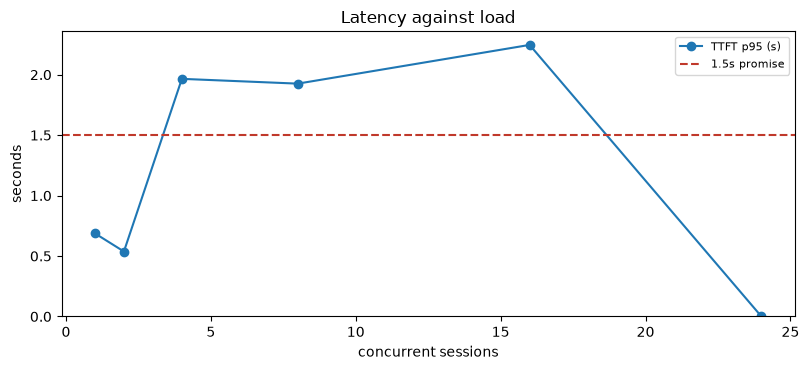

  how to read it: the promise is the dashed line; where the curve crosses it is the limit


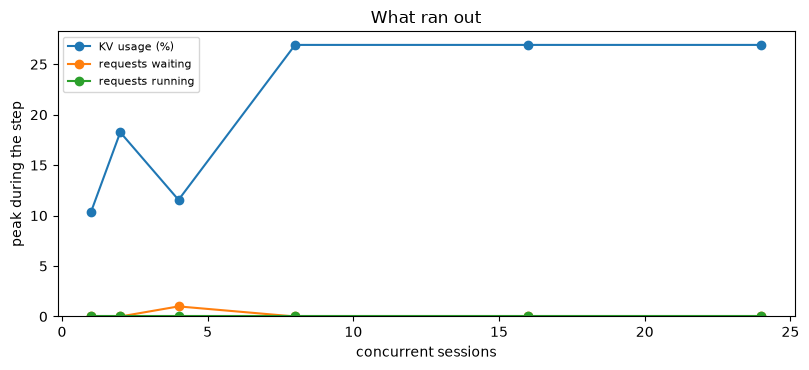

  how to read it: a flat line here means that resource was never scarce
  sessions  requests  TTFT p95  KV peak  waiting peak  running peak
  --------  --------  --------  -------  ------------  ------------
         1         1  0.688s      10.4%             0             0
         2         5  0.537s      18.3%             0             0
         4        23  1.966s      11.6%             1             0
         8       -95  1.926s      26.9%             0             0
        16         0  2.246s      26.9%             0             0
        24         0  0.000s      26.9%             0             0


Report(title='03-capacity', subtitle='', blocks=[_Block(kind='heading', payload='Objective', note=''), _Block(kind='text', payload='How many concurrent sessions hold the TTFT promise, and which resource runs out first — KV cache, decode slots, or scheduling?', note=''), _Block(kind='table', payload=(['SLO under test', 'target'], [['TTFT p95', '1.5s'], ['preemptions', '0'], ['shed rate at target load', '0.05']]), note=''), _Block(kind='text', payload='Falsified by: TTFT p95 crossing 1.5s at any load we intend to serve, or no signal moving at all — which would mean we never reached saturation and cannot claim a capacity limit.', note=''), _Block(kind='heading', payload='1. What the hardware allows', note=''), _Block(kind='table', payload=(['ceiling', 'concurrent sequences', 'why'], [['KV cache', '35.9', '4.1 GiB / 0.11 GiB per prompt'], ['decode slots', '64', '--max-num-seqs, independent of KV']]), note='measured prompt length: 2,137 tokens. The lower number is the ceiling that actually 

In [5]:
report.heading('3. Which signal moved')
xs = [r['sessions'] for r in rows]

report.line('Latency against load', xs,
            {'TTFT p95 (s)': [r['ttft_p95'] for r in rows]},
            xlabel='concurrent sessions', ylabel='seconds',
            hlines={'1.5s promise': SLOS['ttft_p95'].target},
            note='the promise is the dashed line; where the curve crosses it is the limit')

report.line('What ran out', xs,
            {'KV usage (%)':   [r['kv'] * 100 for r in rows],
             'requests waiting': [r['waiting'] for r in rows],
             'requests running': [r['running'] for r in rows]},
            xlabel='concurrent sessions', ylabel='peak during the step',
            note='a flat line here means that resource was never scarce')

report.table(['sessions', 'requests', 'TTFT p95', 'KV peak', 'waiting peak',
              'running peak'],
             [[r['sessions'], f"{r['requests']:.0f}", f"{r['ttft_p95']:.3f}s",
               f"{r['kv']:.1%}", f"{r['waiting']:.0f}", f"{r['running']:.0f}"]
              for r in rows])


## 4. The derived target

The largest session count that still met the promise. Written to
`slos-derived.json` so 04 and 05 read the same operating point rather than
each choosing one.


In [6]:
report.heading('4. The derived target')
target = SLOS['ttft_p95'].target
ok = [r for r in rows if 0 < r['ttft_p95'] <= target]
best = max((r['sessions'] for r in ok), default=0)

kv_moved   = max(r['kv'] for r in rows) - min(r['kv'] for r in rows)
wait_moved = max(r['waiting'] for r in rows) - min(r['waiting'] for r in rows)
scarce = ('KV cache' if kv_moved > 0.05 else
          'queue depth' if wait_moved >= 1 else 'nothing')

report.verdict(best > 0, f'some load level met the {target}s TTFT promise')
report.verdict(scarce != 'nothing',
               'a scarcity signal actually moved during the sweep')
report.slo('ttft_p95', max((r['ttft_p95'] for r in ok), default=0.0))

if best:
    where = set_target_sessions(best, evidence=(
        f'03-capacity swept {SESSIONS} at seed {SEED}; '
        f'TTFT p95 stayed within {target}s through {best} sessions; '
        f'peak KV {max(r["kv"] for r in rows):.1%}, '
        f'peak waiting {max(r["waiting"] for r in rows):.0f}'))
    print(f'  wrote {where.relative_to(ROOT)}')

report.conclusion(
    f'TTFT p95 held within the {target}s promise through {best} concurrent '
    f'sessions, so that is the operating point 04 and 05 will use. '
    + (f'The signal that moved was {scarce}: KV peaked at '
       f'{max(r["kv"] for r in rows):.1%} and the queue reached '
       f'{max(r["waiting"] for r in rows):.0f} waiting requests. An admission '
       f'policy here should read {scarce}.'
       if scarce != 'nothing' else
       'NO signal moved: KV stayed flat and nothing queued. This sweep never '
       'reached saturation, so it cannot support a capacity claim and an '
       'admission A/B run at these loads would compare two policies that both '
       'had nothing to decide. Raise the session count or the prompt length '
       'before trusting 04.'))



4. The derived target
  PASS  some load level met the 1.5s TTFT promise
  PASS  a scarcity signal actually moved during the sweep
  MET   TTFT p95                     0.6875s <= 1.5s
  wrote benchmarking/slos-derived.json

  >> TTFT p95 held within the 1.5s promise through 2 concurrent sessions, so that is the operating point 04 and 05 will use. The signal that moved was KV cache: KV peaked at 26.9% and the queue reached 1 waiting requests. An admission policy here should read KV cache.



Report(title='03-capacity', subtitle='', blocks=[_Block(kind='heading', payload='Objective', note=''), _Block(kind='text', payload='How many concurrent sessions hold the TTFT promise, and which resource runs out first — KV cache, decode slots, or scheduling?', note=''), _Block(kind='table', payload=(['SLO under test', 'target'], [['TTFT p95', '1.5s'], ['preemptions', '0'], ['shed rate at target load', '0.05']]), note=''), _Block(kind='text', payload='Falsified by: TTFT p95 crossing 1.5s at any load we intend to serve, or no signal moving at all — which would mean we never reached saturation and cannot claim a capacity limit.', note=''), _Block(kind='heading', payload='1. What the hardware allows', note=''), _Block(kind='table', payload=(['ceiling', 'concurrent sequences', 'why'], [['KV cache', '35.9', '4.1 GiB / 0.11 GiB per prompt'], ['decode slots', '64', '--max-num-seqs, independent of KV']]), note='measured prompt length: 2,137 tokens. The lower number is the ceiling that actually 

## Verdict


In [7]:
print()
fails = report.failures()
if fails:
    print('NOT SAFE TO PROCEED — fix these first:')
    for f in fails:
        print(f'  - {f}')
else:
    from slos import target_sessions
    print(f'Capacity is {target_sessions()} concurrent sessions. Next: 04-admission')



Capacity is 2 concurrent sessions. Next: 04-admission
